In [1]:
import wrf
from wrf import (CoordPair, vertcross, get_cartopy, getvar, 
                    latlon_coords, to_np, destagger, ll_to_xy, 
                    smooth2d, interplevel)
import numpy as np
from netCDF4 import Dataset 
import matplotlib.pyplot as plt
import pyart
import geocat.viz as gv
from cartopy.mpl.gridliner import LongitudeFormatter, LatitudeFormatter
import os
import glob
from metpy.units import units
import cartopy.crs as crs
import pandas as pd
import xarray as xr
import metpy 
import metpy.calc as mpcalc
import numpy.ma as ma
import matplotlib.ticker as mticker

import cartopy.feature as cfeature
from metpy.interpolate import cross_section
import pkg_resources


## You are using the Python ARM Radar Toolkit (Py-ART), an open source
## library for working with weather radar data. Py-ART is partly
## supported by the U.S. Department of Energy as part of the Atmospheric
## Radiation Measurement (ARM) Climate Research Facility, an Office of
## Science user facility.
##
## If you use this software to prepare a publication, please cite:
##
##     JJ Helmus and SM Collis, JORS 2016, doi: 10.5334/jors.119



In [2]:
os.chdir("/glade/u/home/athornton/wrf_visualization/cold_pool_data/dbz_pv_cp/")
dbzfilenames = (sorted(glob.glob("d03_dbz*test.png")))
pvfilenames = (sorted(glob.glob("pv*test.png")))
cpfilenames = (sorted(glob.glob("c_*test.png")))

In [3]:
dbzletter = ['(a)','(d)','(g)','(j)','(m)']
pvletter = ['(b)','(e)','(h)','(k)','(n)']
cpletter = ['(c)','(f)','(i)','(l)','(o)']

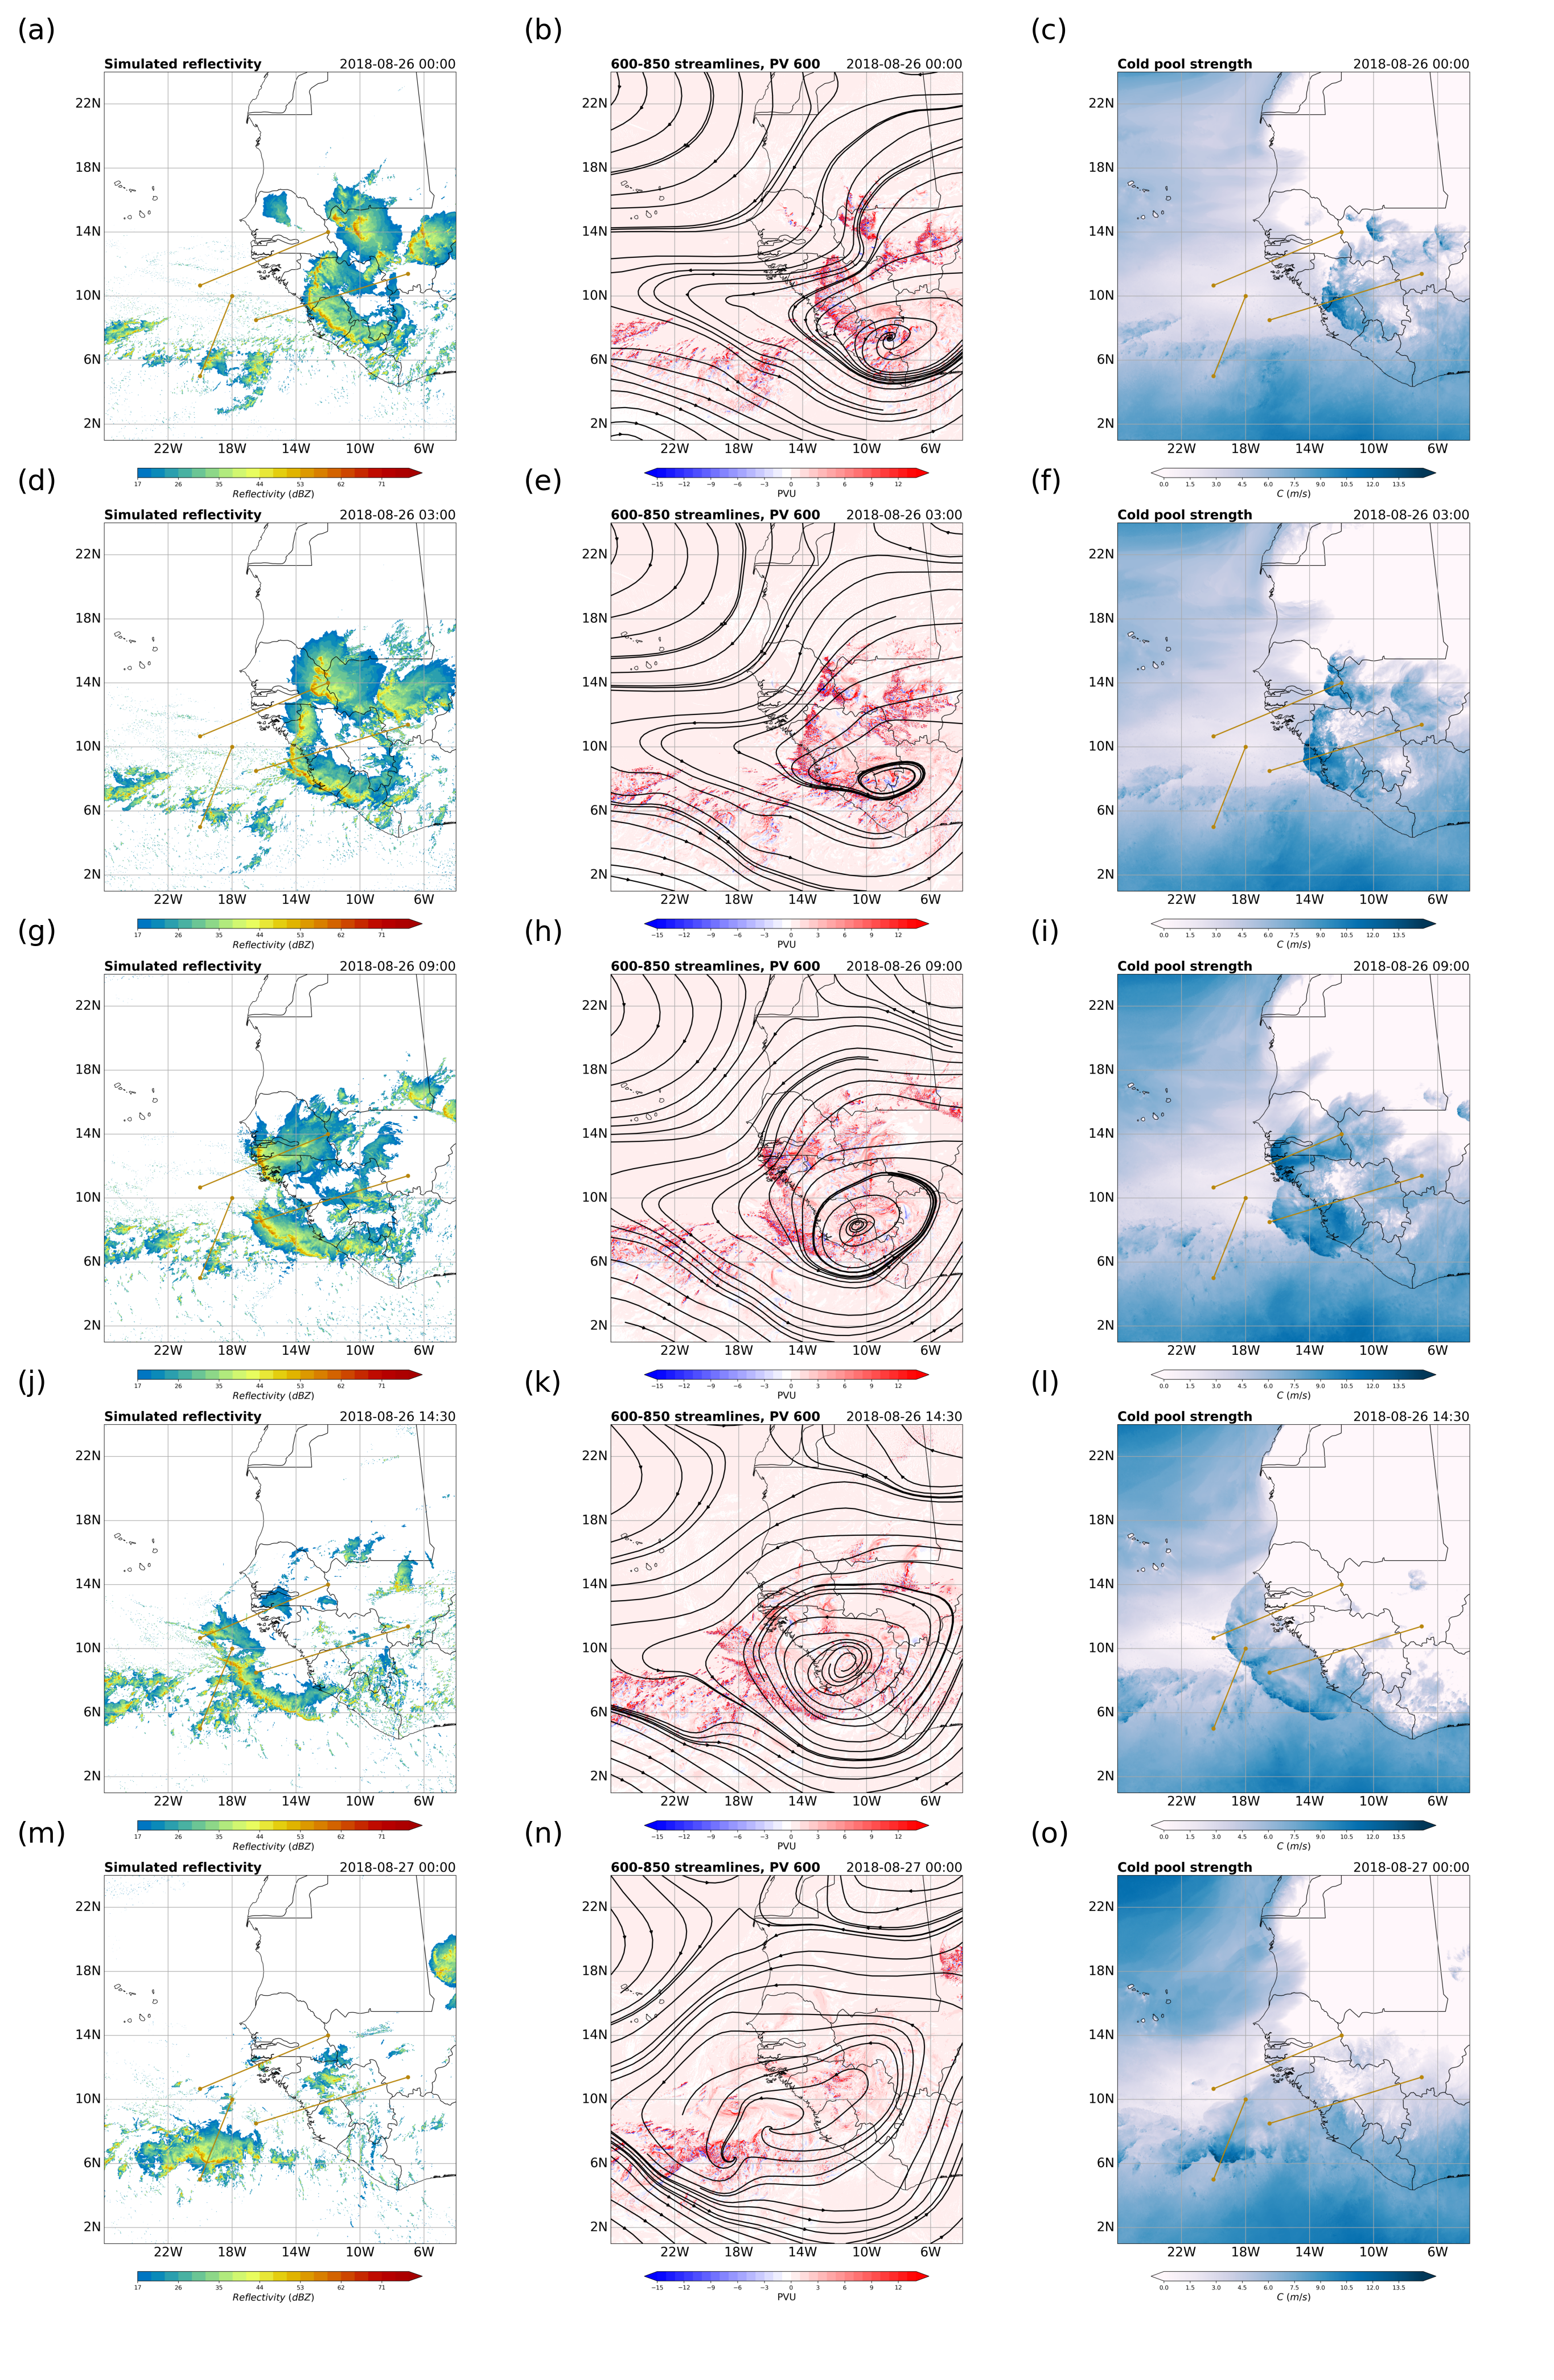

In [4]:
# Source - https://stackoverflow.com/a/68229394
# Posted by Roman Pavelka
# Retrieved 2026-10-25, License - CC BY-SA 4.0

import matplotlib.pyplot as plt

my_dpi=300

fig, axes = plt.subplots(5, 3, figsize=(10,22), dpi=my_dpi)

for row in [0, 1, 2, 3, 4]:
    for column in [0, 1, 2]:
        ax = axes[row, column]
        if column == 0:
            image = plt.imread(dbzfilenames[row])
            ax.set_title(dbzletter[row], loc='left')
        if column == 1:
            image = plt.imread(pvfilenames[row])
            ax.set_title(pvletter[row], loc='left')
        if column == 2:
            image = plt.imread(cpfilenames[row])
            ax.set_title(cpletter[row], loc='left')
        ax.axis('off')
        ax.imshow(image)

plt.subplots_adjust(left=0.01,
                bottom=0.18,
                right=0.9,
                top=0.9,
                wspace=0,
                hspace=-0.5)
#axes[0,0].set_title('850-600 streamlines, 600 PV', fontsize=12)#, weight='bold')
#plt.tight_layout()
#plt.show()
#plt.savefig('sim_overview.png', bbox_inches='tight')
